<a href="https://colab.research.google.com/github/HeloiseAlbot/PushQuantum_Hackathon2026_QORO_NetworkDesignProblem/blob/main/Solution002_RefinePartition.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QOBLIB 08 – Network Design: best placement of a known shape

Uses the hackathon helper **`qoblib_tools`** (put `qoblib_tools.py` next to this notebook; it needs `dimod`, `numpy`, `scipy`, `requests`)
as the referee for data loading and scoring:

* `qt.load_network_demand(n)` – demand matrix of `networkNN`
* `qt.read_network_solution`, `qt.is_valid_topology`, `qt.check_network_solution` – solution I/O and checks
* `qt.route_min_congestion(demand, arcs)` – the **official score** of a topology (LP rounded up, in 1/1000 units)
* `qt.route_integral`, `qt.write_network_solution` – integer flows and a submittable `.sol` file

**Plan.**
1. Download the best-known solutions for `N` nodes from QOBLIB (via `qt.fetch_qoblib_file`) and keep the best one: its **shape** (unlabeled digraph).
2. Search over **placements** of that shape (relabelings; demand fixed) for a lower score.
   * Stage 1: simulated annealing on the QAP surrogate `sum T_ij d(s_i,s_j)/(n p)`, which is also a valid **lower bound** on the LP value.
   * Stage 2: exact scoring of the best candidates with `qt.route_min_congestion`.
   * Stage 3: exact 2-swap local search with kicks, pruned by the lower bound.
3. Export the best topology as a `.sol` file and validate it with `qt.check_network_solution`.

> I could not open the repo's `08-network/solutions` folder while writing this, so the notebook **discovers** solution files through the
> GitHub API and scores every candidate it can parse. Adjust `SOLUTION_RELS` by hand if the automatic discovery misses the file you want.

In [4]:
!wget -q -O qoblib_tools.py https://raw.githubusercontent.com/QoroQuantum/pushquantum-hackathon-2026/main/qoblib_tools.py
!pip install -q dimod

In [30]:
# !pip install numpy scipy networkx requests matplotlib dimod
import os, re, json, time, math, itertools
import numpy as np, requests, networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr

import qoblib_tools as qt

# ----------------------------- configuration -----------------------------
N    = 24          # number of nodes
P    = 2           # QOBLIB network design: in/out degree
SEED = 0
REPO, BRANCH, FOLDER = "ZIB-AOPT/QOBLIB", "main", "08-network"

# Leave None for automatic discovery, or give repo-relative paths, e.g. ["08-network/solutions/....sol"]
SOLUTION_RELS = None

## 1. Demand and best-known solution(s)

In [31]:
demand = qt.load_network_demand(N)                 # demand[k, i]: traffic k -> i, raw units (qt scales by 1000)
Tm = demand.astype(float) * qt.INTSCALE            # same units as qt's scores
print("demand", demand.shape, "| max", demand.max(), "| total", demand.sum())

def gh_paths():
    r = requests.get(f"https://api.github.com/repos/{REPO}/git/trees/{BRANCH}?recursive=1", timeout=60)
    r.raise_for_status(); js = r.json()
    if js.get("truncated"): print("WARNING: tree truncated")
    return [e["path"] for e in js["tree"] if e["type"] == "blob" and e["path"].startswith(FOLDER + "/")]

if SOLUTION_RELS is None:
    try:
        PATHS = gh_paths()
        pat = re.compile(rf"(?<!\d){N}(?!\d)")
        SOLUTION_RELS = [p for p in PATHS if re.search(r"/(solutions|submissions)/", p)
                         and p.endswith(".sol") and pat.search(p[len(FOLDER):])]
    except Exception as e:
        SOLUTION_RELS = []; print("Could not list the repo:", e)
print(f"{len(SOLUTION_RELS)} candidate solution file(s):"); [print("  ", p) for p in SOLUTION_RELS]

demand (24, 24) | max 100 | total 11069
3 candidate solution file(s):
   08-network/solutions/network24.bst.sol
   08-network/submissions/20250102_MIP_Schicker/network24/network24_solution.sol
   08-network/submissions/20260818_ParallelTempering_Gupta/network24/network24_solution.sol


[None, None, None]

In [32]:
_cache = {}
def score(arcs):
    # official score via qoblib_tools; cached
    key = tuple(sorted(arcs))
    if key not in _cache: _cache[key] = qt.route_min_congestion(demand, key)
    return _cache[key]

rows = []
for rel in SOLUTION_RELS:
    try:
        path = qt.fetch_qoblib_file(rel)
        z_file, arcs, _ = qt.read_network_solution(path)
        if not qt.is_valid_topology(N, arcs): raise ValueError("not a valid degree-2 topology on N nodes")
        r = score(arcs)
        rows.append((r.objective, r.z_lp, z_file, rel, arcs))
    except Exception as e:
        print(f"  skipped {rel}: {e}")
rows.sort(key=lambda x: x[0])
for obj, zlp, zf, rel, _ in rows: print(f"  objective {obj:,.0f} | LP {zlp:,.1f} | z in file {zf:,} | {rel}")

if rows:
    base_obj, base_lp, _, base_rel, base_arcs = rows[0]
    print("\nBest imported solution:", base_rel)
else:
    print("\nNo solution file could be used -> fallback: best of 300 random topologies (NOT the QOBLIB best).")
    rng0 = np.random.default_rng(SEED)
    cand = [qt.random_topology(N, rng0) for _ in range(300)]
    base_arcs = min(cand, key=lambda a: score(a).z_lp)
    r = score(base_arcs); base_obj, base_lp, base_rel = r.objective, r.z_lp, "(random fallback)"
print(f"baseline objective = {base_obj:,.0f}   (LP {base_lp:,.1f})")

  objective 663,688 | LP 663,687.5 | z in file 663,688 | 08-network/solutions/network24.bst.sol
  objective 702,028 | LP 702,027.8 | z in file 702,028 | 08-network/submissions/20260818_ParallelTempering_Gupta/network24/network24_solution.sol
  objective 772,703 | LP 772,702.7 | z in file 779,410 | 08-network/submissions/20250102_MIP_Schicker/network24/network24_solution.sol

Best imported solution: 08-network/solutions/network24.bst.sol
baseline objective = 663,688   (LP 663,687.5)


## 2. Shape, distances, lower bounds, symmetry
`Adj` is the shape in *position* space. A placement `s` puts logical node `i` at position `s[i]`; the labeled digraph has adjacency `Adj[s][:, s]`
(arc `(i, j)` exists iff `(s[i], s[j])` is an arc of the shape).

Two **valid lower bounds** on the LP value (used for pruning):
* `floor` (placement-independent): `max(max row sum, max column sum)/p` (each node uses only `p` outgoing and `p` incoming arcs).
* `avg_bound(s)`: `sum T_ij d(s_i,s_j)/(n p)` (every unit of flow uses at least `d` of the `n p` arcs).

In [33]:
n = N
Adj = np.zeros((n, n), dtype=np.int8)
for i, j in base_arcs: Adj[i, j] = 1
D = shortest_path(csr_matrix(Adj), unweighted=True, directed=True)
assert np.isfinite(D).all(), "shape is not strongly connected"

floor = max(Tm.sum(1).max(), Tm.sum(0).max()) / P
def avg_bound(s): return float((Tm * D[np.ix_(s, s)]).sum()) / (n * P)
def labeled(s):   return Adj[np.ix_(s, s)]
def arcs_of(s):   return [tuple(map(int, a)) for a in np.argwhere(labeled(s))]
def z_of(s):      return score(arcs_of(s)).z_lp          # LP value (search objective); official score = ceil

ident = np.arange(n)
print(f"floor (node bound)            : {floor:,.1f}")
print(f"avg_bound(imported placement) : {avg_bound(ident):,.1f}")
print(f"LP value of imported placement: {z_of(ident):,.1f}   (official objective {base_obj:,.0f})")

def count_aut(A, cap=20000):
    G = nx.from_numpy_array(A, create_using=nx.DiGraph)
    c = 0
    for _ in nx.isomorphism.DiGraphMatcher(G, G).isomorphisms_iter():
        c += 1
        if c >= cap: return f">={cap}"
    return c
aut = count_aut(Adj)
print("|Aut(shape)| =", aut, "-> distinct labelings =", f"{math.factorial(n)/aut:.3e}" if isinstance(aut, int) else "huge")

floor (node bound)            : 327,000.0
avg_bound(imported placement) : 624,083.3
LP value of imported placement: 663,687.5   (official objective 663,688)
|Aut(shape)| = 1 -> distinct labelings = 6.204e+23


## 3. Stage 1 – simulated annealing on the QAP surrogate
Placements that give the same *labeled* digraph (they differ by an automorphism) are deduplicated by their adjacency bytes.

In [34]:
rng = np.random.default_rng(SEED)

def sa_surrogate(s0, iters, rng):
    s = s0.copy(); cur = avg_bound(s); c0 = max(cur, 1.0)
    t_hi, t_lo = 0.05 * c0, 1e-3 * c0
    seen = {tuple(s): cur}
    for it in range(iters):
        temp = t_hi * (t_lo / t_hi) ** (it / iters)
        i, j = rng.choice(n, 2, replace=False)
        s[i], s[j] = s[j], s[i]
        c = avg_bound(s)
        if c <= cur or rng.random() < math.exp((cur - c) / temp):
            cur = c; seen[tuple(s)] = c
        else:
            s[i], s[j] = s[j], s[i]
    return seen

RESTARTS, ITERS = 40, 4000
pool = {tuple(ident): avg_bound(ident)}
t0 = time.time()
for r_ in range(RESTARTS):
    pool.update(sa_surrogate(rng.permutation(n), ITERS, rng))
print(f"SA done in {time.time()-t0:.1f}s; pooled {len(pool)} placements")

uniq = {}
for s, c in sorted(pool.items(), key=lambda kv: kv[1]):
    key = labeled(np.array(s)).tobytes()
    if key not in uniq: uniq[key] = (np.array(s), c)
cands = list(uniq.values())
print("distinct labeled digraphs:", len(cands), "| best surrogate:", f"{cands[0][1]:,.1f}")

SA done in 5.1s; pooled 80110 placements
distinct labeled digraphs: 80110 | best surrogate: 624,083.3


## 4. Stage 2 – official scoring of the top candidates (and how good is the surrogate?)

qt.route_min_congestion on 80 candidates: 3.1s
best LP among candidates: 663,687.5 | baseline: 663,687.5
Spearman(surrogate, exact) on candidates = 0.039


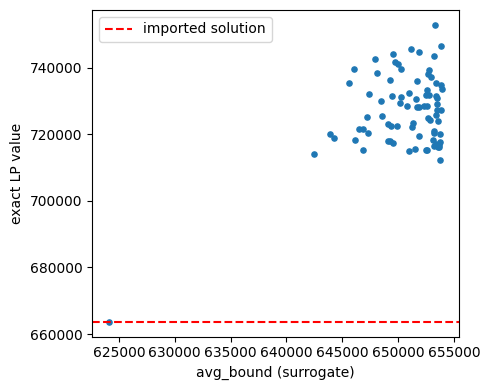

In [35]:
K = 80
t0 = time.time()
evald = [(s, c, z_of(s)) for s, c in cands[:K]]
print(f"qt.route_min_congestion on {len(evald)} candidates: {time.time()-t0:.1f}s")
evald.sort(key=lambda x: x[2])
print(f"best LP among candidates: {evald[0][2]:,.1f} | baseline: {z_of(ident):,.1f}")

sur = np.array([e[1] for e in evald]); ex = np.array([e[2] for e in evald])
print(f"Spearman(surrogate, exact) on candidates = {spearmanr(sur, ex).correlation:.3f}")
plt.figure(figsize=(5, 4)); plt.scatter(sur, ex, s=14)
plt.axhline(z_of(ident), ls="--", c="r", label="imported solution")
plt.xlabel("avg_bound (surrogate)"); plt.ylabel("exact LP value"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Stage 3 – exact local search (2-swaps + iterated kicks), pruned by the lower bound
A neighbor is scored exactly only if `max(floor, avg_bound) < current best` (otherwise it provably cannot improve).

In [7]:
def local_search(s, max_iter=100):
    s = s.copy(); cur = z_of(s); pruned = evaluated = 0
    for _ in range(max_iter):
        best_val, best_s = cur, None
        for i, j in itertools.combinations(range(n), 2):
            s2 = s.copy(); s2[i], s2[j] = s2[j], s2[i]
            if max(floor, avg_bound(s2)) >= best_val - 1e-9: pruned += 1; continue
            v = z_of(s2); evaluated += 1
            if v < best_val - 1e-6: best_val, best_s = v, s2
        if best_s is None: break
        s, cur = best_s, best_val
    return s, cur, pruned, evaluated

KICKS, KICK_SIZE, STARTS = 15, 3, 5
best_s, best_z = ident.copy(), z_of(ident)
for e in evald:
    if e[2] < best_z - 1e-6: best_s, best_z = e[0].copy(), e[2]
t0 = time.time(); tot_pruned = tot_eval = 0
starts = [ident] + [e[0] for e in evald[:STARTS]]
for s_start in starts:
    s, z, pr, ev = local_search(s_start); tot_pruned += pr; tot_eval += ev
    if z < best_z - 1e-6: best_s, best_z = s.copy(), z
    for _ in range(KICKS):
        s2 = s.copy()
        for _ in range(KICK_SIZE):
            i, j = rng.choice(n, 2, replace=False); s2[i], s2[j] = s2[j], s2[i]
        s2, z2, pr, ev = local_search(s2); tot_pruned += pr; tot_eval += ev
        if z2 < z - 1e-6: s, z = s2, z2
        if z2 < best_z - 1e-6: best_s, best_z = s2.copy(), z2
print(f"local search: {time.time()-t0:.1f}s | official scorings: {tot_eval} | pruned by bound: {tot_pruned}")

local search: 190.8s | official scorings: 35047 | pruned by bound: 443


## 6. Result

baseline objective (imported): 343,091   [08-network/solutions/network14.bst.sol]
best objective found          : 342,228   (LP 342,227.3)   +0.252% vs baseline
lower bounds at best placement: floor=220,000.0, avg_bound=305,785.7
placement s (logical node -> shape position, 1-based): [1, 2, 3, 6, 5, 4, 7, 8, 9, 10, 11, 12, 13, 14]
arcs (1-based): [(1, 2), (1, 6), (2, 3), (2, 7), (3, 5), (3, 13), (4, 1), (4, 8), (5, 6), (5, 7), (6, 4), (6, 12), (7, 9), (7, 11), (8, 10), (8, 14), (9, 3), (9, 8), (10, 9), (10, 13), (11, 1), (11, 10), (12, 2), (12, 14), (13, 4), (13, 12), (14, 5), (14, 11)]


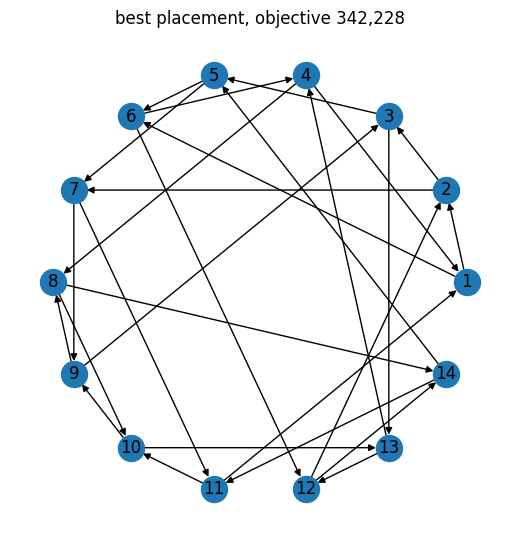

In [8]:
best_arcs = sorted(arcs_of(best_s))
assert qt.is_valid_topology(N, best_arcs)
res = qt.route_min_congestion(demand, best_arcs)
print(f"baseline objective (imported): {base_obj:,.0f}   [{base_rel}]")
print(f"best objective found          : {res.objective:,.0f}   (LP {res.z_lp:,.1f})   {100*(base_obj-res.objective)/base_obj:+.3f}% vs baseline")
print(f"lower bounds at best placement: floor={floor:,.1f}, avg_bound={avg_bound(best_s):,.1f}")
print("placement s (logical node -> shape position, 1-based):", (best_s + 1).tolist())
print("arcs (1-based):", [(i + 1, j + 1) for i, j in best_arcs])

G = nx.DiGraph(); G.add_nodes_from(range(n)); G.add_edges_from(best_arcs)
plt.figure(figsize=(5, 5)); nx.draw_circular(G, with_labels=True, labels={i: i + 1 for i in range(n)}, node_size=350, arrowsize=10)
plt.title(f"best placement, objective {res.objective:,.0f}"); plt.show()

## 7. Export a submittable `.sol` file and validate it with the official checker port
Integer flows come from `qt.route_integral` (MILP; may take a while, hence the time limit).

In [9]:
routing = qt.route_integral(demand, best_arcs, time_limit=120)
out = f"network{N}_best_placement.sol"
z_written = qt.write_network_solution(out, N, routing)
ok, max_flow, msg = qt.check_network_solution(out, N, demand)
print(f"written {out}: z = {z_written:,} | checker: valid={ok}, max_flow={max_flow:,}, {msg}")
# Compare z_written with the best known value for this size before submitting (see CONTRIBUTING.md in the repo).

written network14_best_placement.sol: z = 342,228 | checker: valid=True, max_flow=342,228, valid


### Notes
* The search only explores **placements of one shape**. To explore other shapes, loop over the other parsed solutions in `rows`, or generate
  shapes with `qt.random_topology`, and rerun sections 2–6.
* If the imported solution is already optimal for its shape, the notebook reports `+0.000%`; that is informative in itself.
* The official objective is `ceil` of the LP value (per `qt.route_min_congestion`); the search compares LP values so it can break ties.
* Tunables: `RESTARTS`, `ITERS`, `K`, `STARTS`, `KICKS`, `KICK_SIZE`.